# Mark Ayman

# Telco Customer Churn XGBoost Modeling

**Author:** Mark Ayman  
**Objective:** to preform full Analysis using PYTHON

## Introduction

This notebook performs a full data analysis workflow
The goal of this analysis is to:
- Understand the dataset structure
- Clean and preprocess the data
- Perform exploratory data analysis (EDA)
- Identify patterns and trends
- Generate business insights

## import libraries

In [27]:
from google.colab import files
import math
import pickle
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline

## load dataset

In [2]:
# Local on collab
df = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (2).csv


In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

## Data Overview

In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
df.describe(include = 'O')

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## Data Cleaning

### Data Types

In [12]:
df = df.replace(' ', np.nan)
df["TotalCharges"] = df["TotalCharges"].astype("float")
df["TotalCharges"] = df["TotalCharges"].replace(' ', df["TotalCharges"].median())

In [13]:
df = df.replace('No internet service', 'No')

In [35]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

## Data Visualization

In [14]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

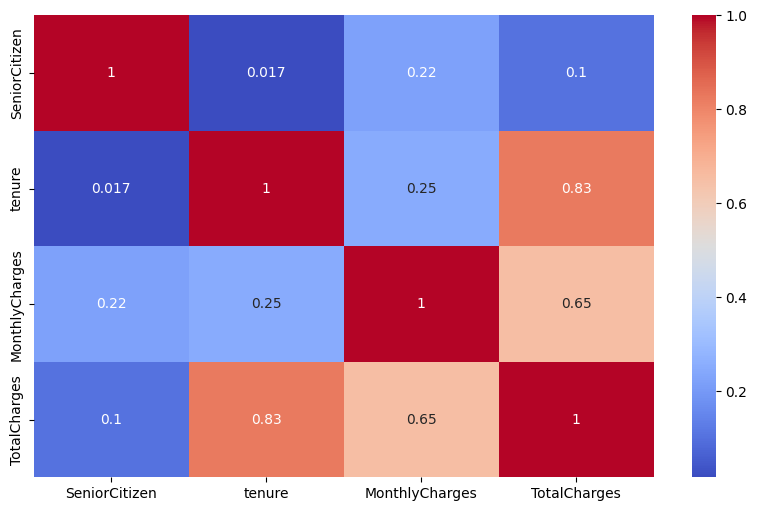

In [15]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

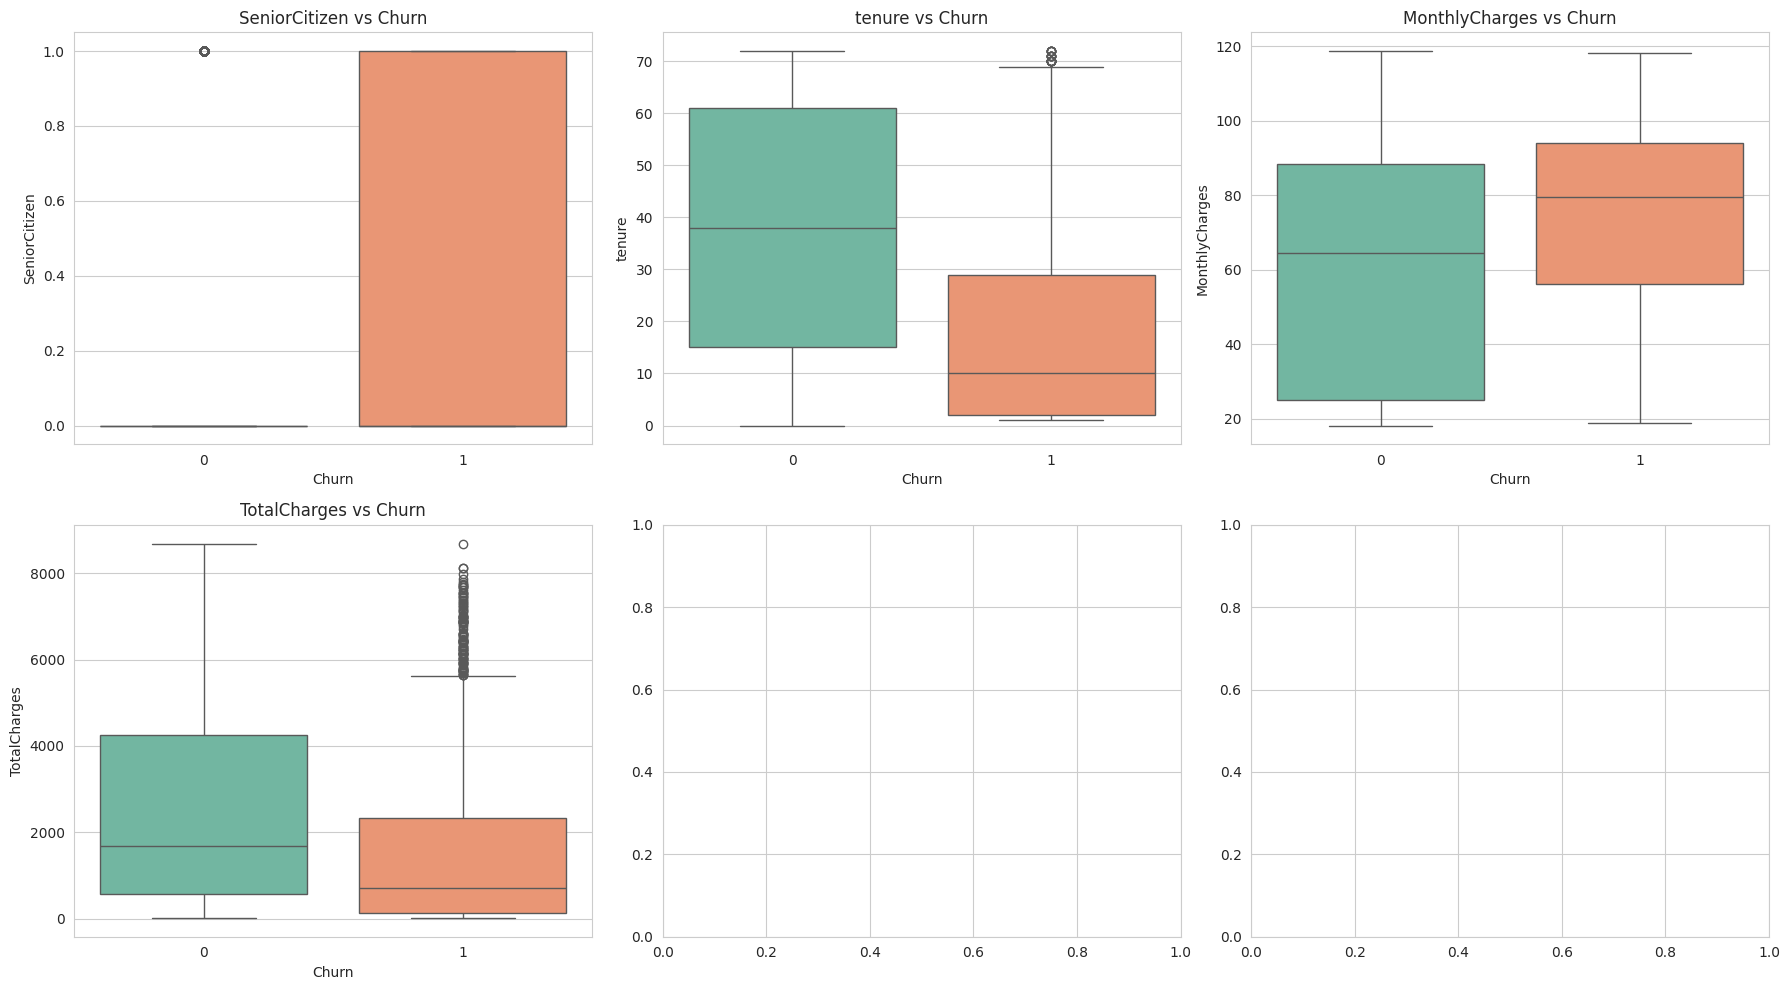

In [51]:
feature_columns = numerical_cols
target_columns = ['Churn']

sns.set_style("whitegrid")

for target in target_columns:

    n_cols = 3
    n_rows = math.ceil(len(feature_columns) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
    axes = axes.flatten()

    for ax, feature in zip(axes, feature_columns):
        sns.boxplot(
            x=target,
            y=feature,
            hue=target,
            data=df,
            ax=ax,
            palette="Set2",
            legend=False
        )

        ax.set_title(f"{feature} vs {target}")
        ax.set_xlabel(target)
        ax.set_ylabel(feature)

    plt.tight_layout()
    plt.show()

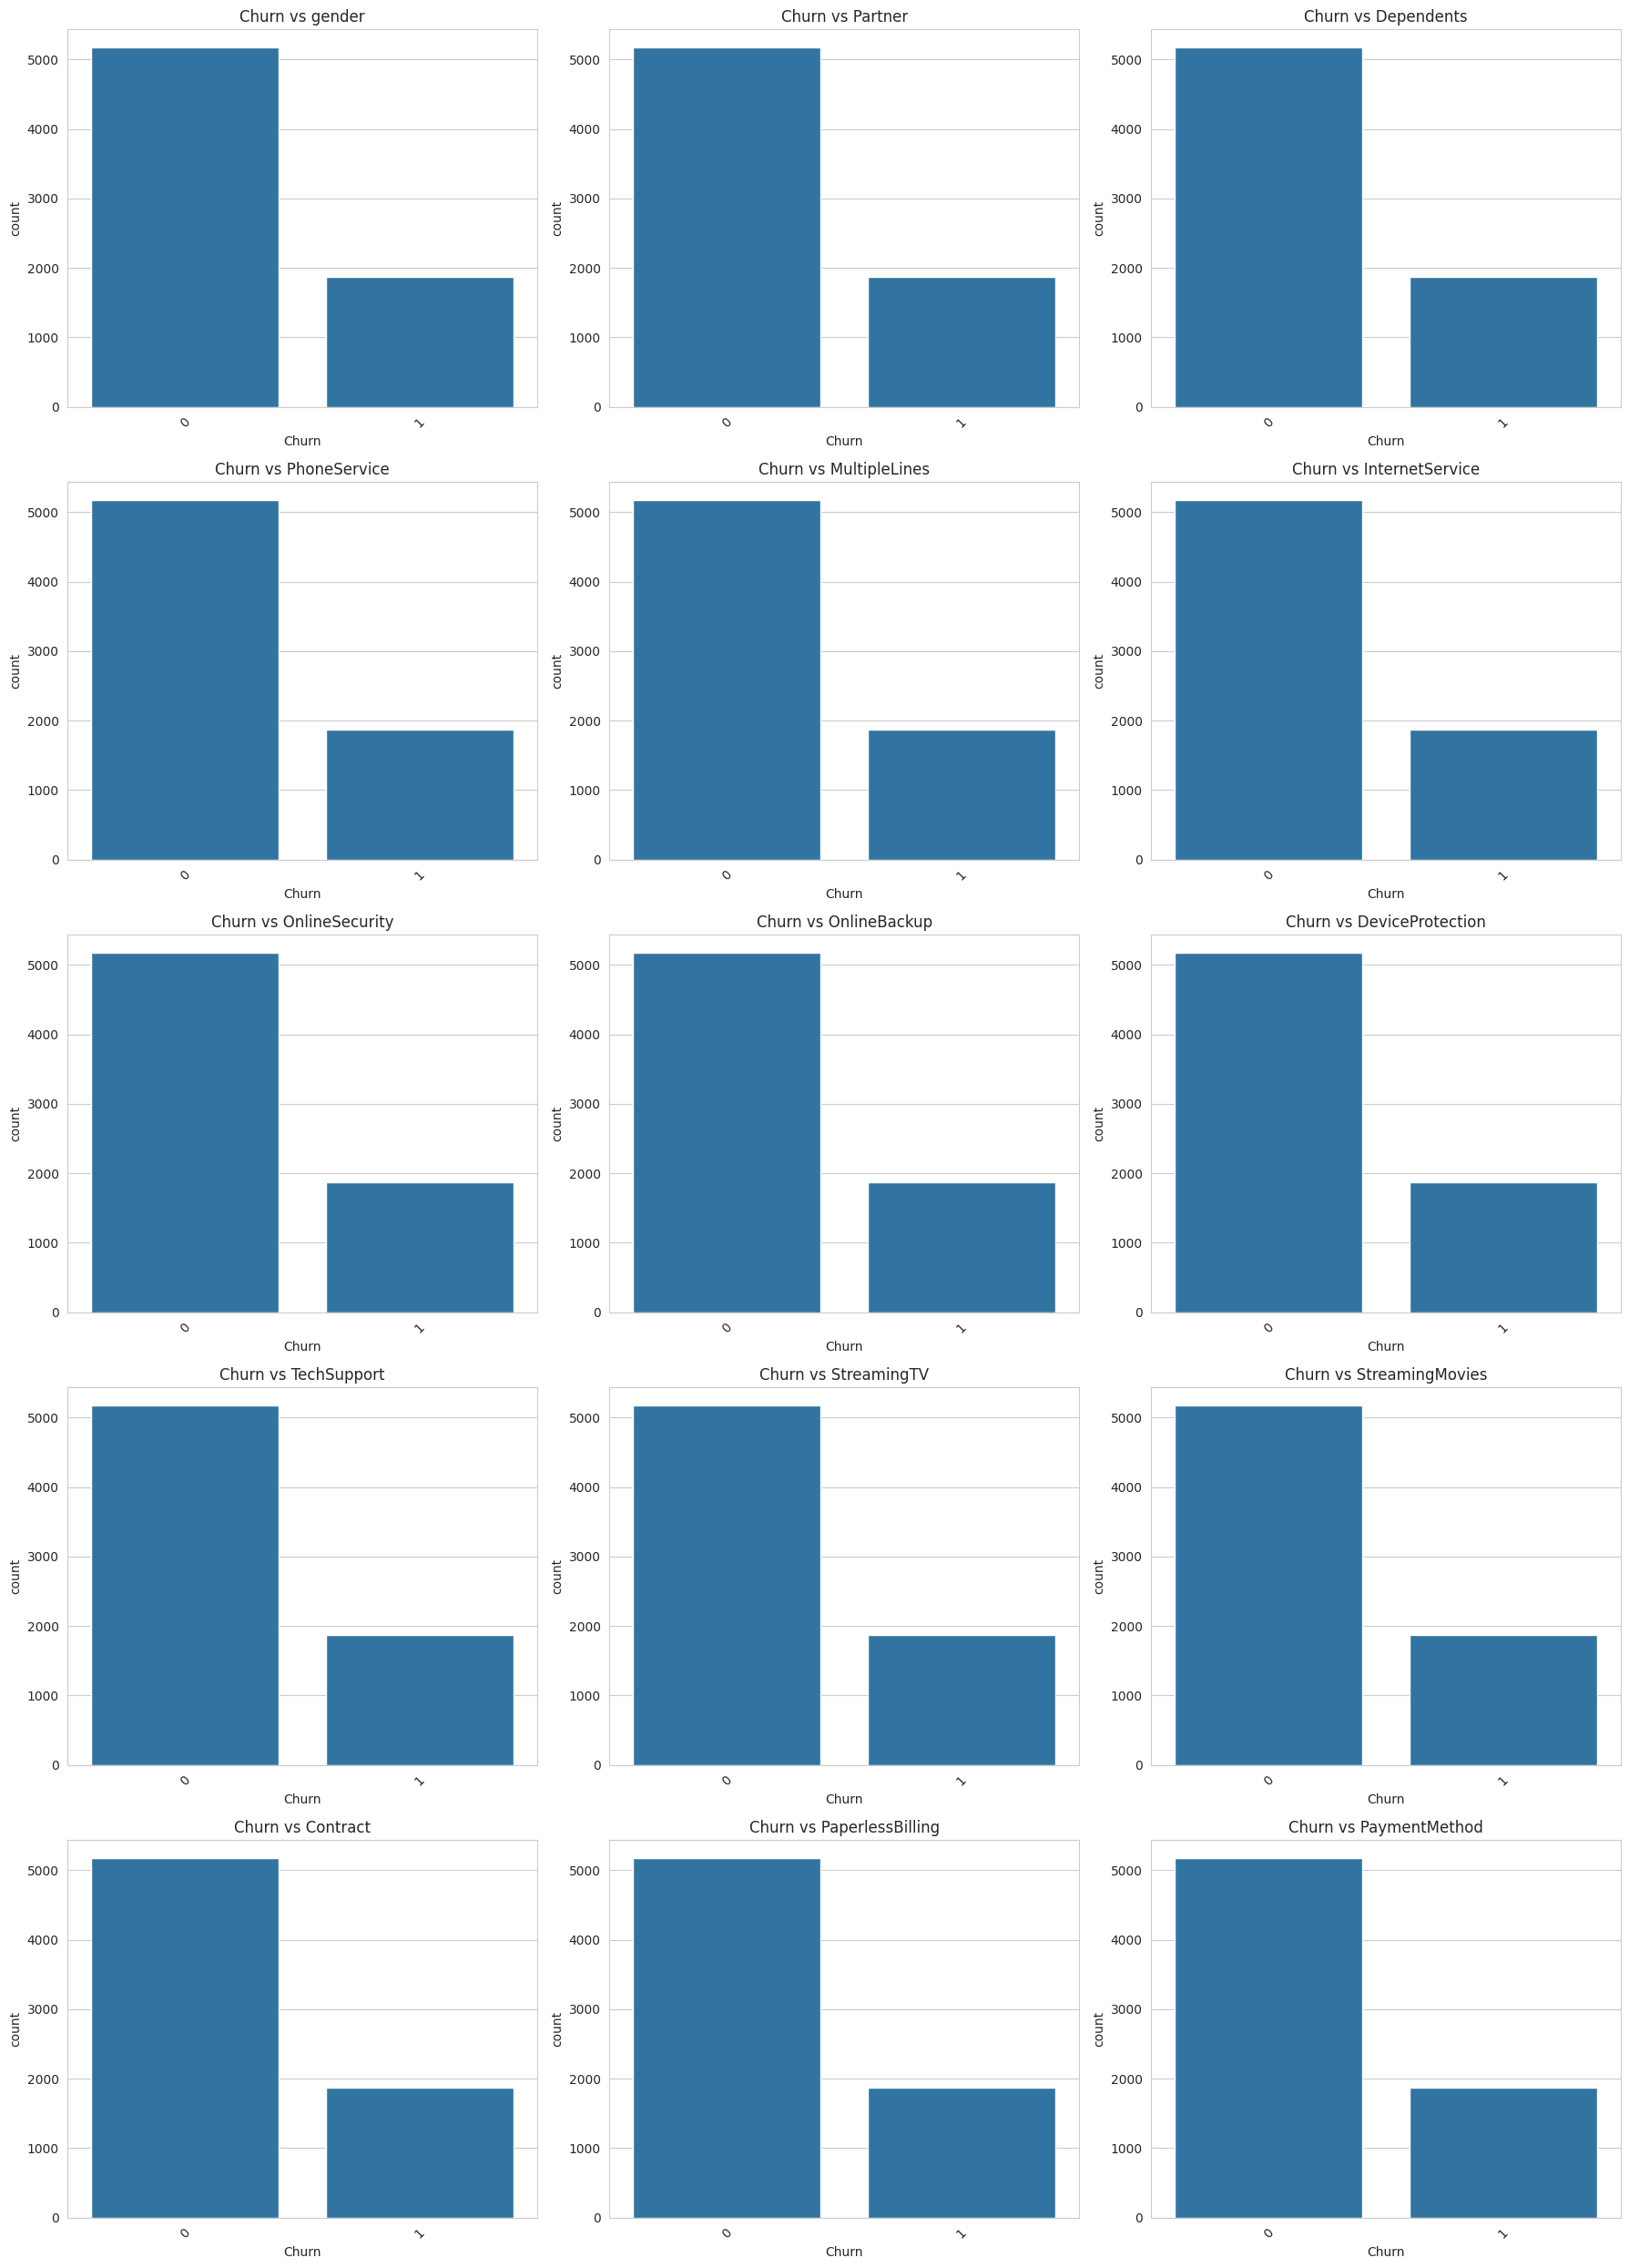

In [50]:
sns.set_style("whitegrid")

n_plots = len(categorical_cols)
n_cols = 3

n_rows = math.ceil(n_plots / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(6 * n_cols, 5 * n_rows)
)

axes = axes.flatten()

for plot_idx, col in enumerate(categorical_cols):
    if col == "Churn":
        continue
    sns.countplot(
        data=df,
        x="Churn",
        ax=axes[plot_idx]
    )

    axes[plot_idx].set_title(f"Churn vs {col}")
    axes[plot_idx].tick_params(axis="x", rotation=45)

for ax in axes[n_plots:]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

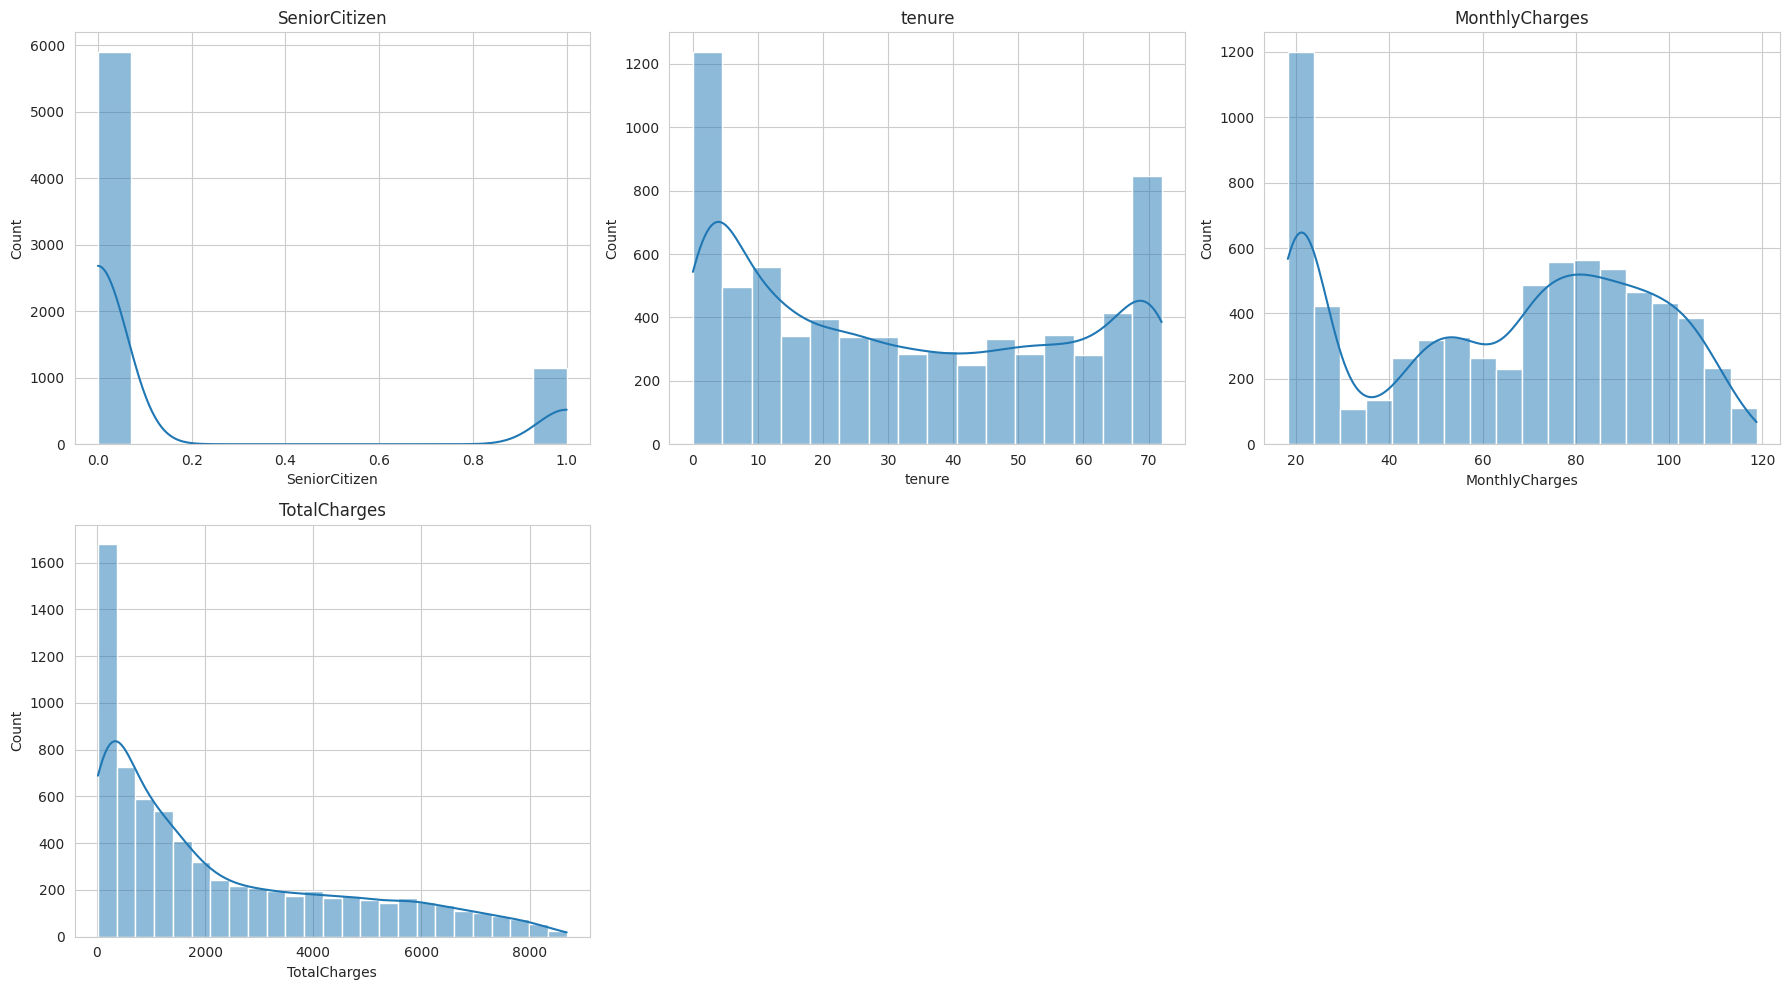

In [18]:
sns.set_style("whitegrid")

n_plots = len(numerical_cols)

if n_plots == 0:
    print("No numerical columns found.")
else:
    n_cols = 3
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))

    if n_plots == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    plot_idx = 0

    for col in numerical_cols:
        sns.histplot(
            data=df,
            x=col,
            kde=True,
            ax=axes[plot_idx]
        )

        axes[plot_idx].set_title(col)
        plot_idx += 1

    for ax in axes[plot_idx:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

## Model

In [19]:
df = df.drop("customerID", axis=1)

### Separate Features and Target

In [36]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [37]:
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns

Numerical Columns: Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')
Categorical Columns: Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


### Create the Preprocessing Pipeline

In [44]:
num_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, numerical_cols),
    ("cat", cat_pipeline, categorical_cols)
])

### Train-Test Split

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### Select Model

In [46]:
model = XGBClassifier()

### Build the Complete Pipeline

In [47]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", model)
])

### Train & Predict

In [48]:
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

### Evaluate

0.7828246983676366
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1035
           1       0.59      0.59      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409



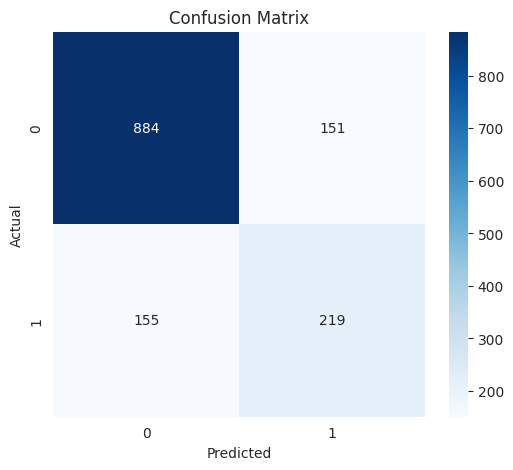

In [49]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### Save the Pipeline

In [52]:
with open("pipeline.pkl", "wb") as file:
    pickle.dump(pipeline, file)

## Key Insights



### Data Overview and Cleaning
- The dataset contains 7043 customer records with 20 features and a `Churn` target variable.
- No duplicate rows were found.
- The `TotalCharges` column was initially an object type and contained empty strings, which were converted to `NaN` and then imputed with the median before casting to float.
- Categorical features with 'No internet service' or 'No phone service' entries were simplified to 'No'.
- The `Churn` target variable was encoded numerically (0 for No, 1 for Yes).

### Exploratory Data Analysis (EDA)
- **Churn Rate:** The dataset shows a class imbalance, with a significantly higher number of non-churned customers compared to churned customers.
- **Correlations:**
    - `tenure` and `TotalCharges` show a negative correlation with churn (longer tenure and higher total charges are associated with lower churn).
    - `MonthlyCharges` shows a positive correlation with churn (higher monthly charges are associated with higher churn).
- **Key Factors Influencing Churn:**
    - **Contract Type:** Customers with Month-to-month contracts have a much higher churn rate than those with One year or Two year contracts.
    - **Internet Service:** Customers with 'Fiber optic' internet service churn more frequently.
    - **Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies:** Absence of these services often correlates with higher churn.
    - **Paperless Billing:** Customers using paperless billing tend to churn more.
    - **Payment Method:** Electronic checks are associated with a higher churn rate.
    - **SeniorCitizen:** Senior citizens show a slightly higher churn rate.

### Model Performance
- The XGBoost model, with SMOTE for handling class imbalance, achieved an accuracy of approximately 78.3% on the test set.
- **Precision and Recall for Churn (Class 1):** The model has a precision of 59% and a recall of 59% for the churned class. This indicates that while the model correctly identifies 59% of actual churners (recall), only 59% of its positive predictions are correct (precision). This is a balanced performance for the minority class, likely due to SMOTE.
- **Precision and Recall for Non-Churn (Class 0):** The model performs very well for the non-churned class, with 85% precision and 85% recall.
- The confusion matrix shows that the model has a notable number of false positives (predicting churn when there is no churn) and false negatives (predicting no churn when there is churn) for the churned class.

## Conclusions

### Strategic Recommendations
- **Contract Length:** Incentivize customers to switch from month-to-month contracts to longer-term contracts (one-year or two-year) through discounts or exclusive offers.
- **Service Bundles:** Promote and enhance value-added services like Online Security, Tech Support, and Device Protection, especially for 'Fiber optic' internet users, as their absence is a churn indicator.
- **Billing and Payment:** Encourage customers to opt for payment methods other than electronic checks, and review the paperless billing process to identify any friction points contributing to churn.
- **Customer Engagement:** Implement proactive engagement strategies for customers with short tenures and those identified as high-risk through the model, offering personalized support or loyalty programs.

### Model Limitations and Future Work
- The model's performance for identifying churners, while reasonable, could be further improved. Future work might include:
    - **Feature Engineering:** Creating new features from existing ones (e.g., combining service types, calculating service usage ratios).
    - **Advanced Imbalance Handling:** Experimenting with other techniques beyond SMOTE, such as NearMiss, ADASYN, or ensemble methods designed for imbalanced data.
    - **Hyperparameter Tuning:** More extensive tuning of the XGBoost classifier's hyperparameters could yield better results.
    - **Alternative Models:** Exploring other classification algorithms like LightGBM, CatBoost, or deep learning models.
- The current model provides a solid foundation for predicting customer churn, and its insights can directly inform business strategies to retain customers.